# Introduction to Outlier and Novelty Detection & LOF Preview

Data tak lazim (anomalies) terbagi menjadi dua kategori utama:
1. Outliers: Data pencilan yang sudah ada di dalam dataset latih (training set). Biasanya merupakan hasil noise, eror sensor, atau kejadian langka. Algoritma harus tahan terhadap kontaminasi data latih.
2. Novelties: Data pencilan yang belum pernah ada pada data latih, dan baru muncul pada saat prediksi (inference time). Model dilatih menggunakan data bersih (inliers saja), lalu bertugas menolak data baru yang keluar dari distribusi normal.

Local Outlier Factor (LOF):
Metode berbasis kerapatan (density-based) yang membandingkan kerapatan lokal (local density) di sekitar suatu titik dengan kerapatan tetangga-tetangganya. Titik yang berada pada area yang jauh lebih renggang dibanding tetangganya akan ditandai sebagai outlier. Parameter contamination menentukan estimasi persentase outlier pada dataset (misal 0.05 = $5\%$).

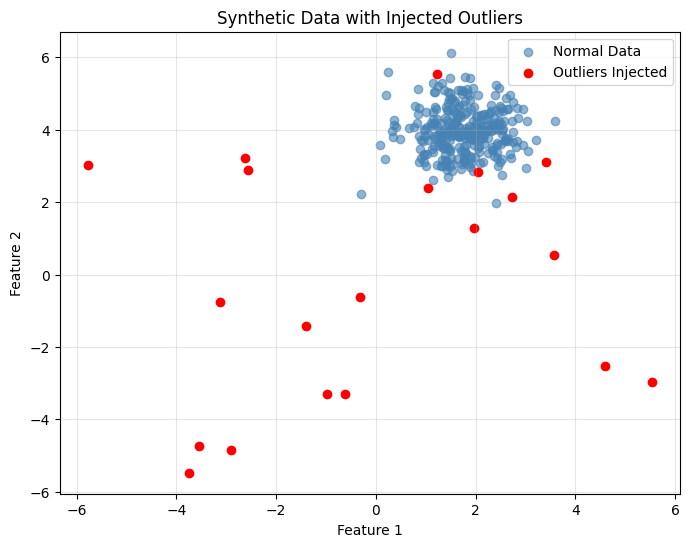

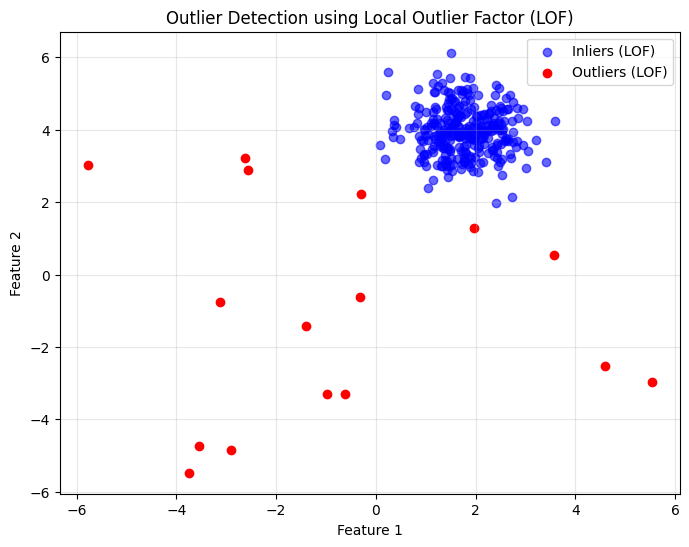

Normal Data Count: 300 | Outliers Count: 20
Detected Outliers: 16 points


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.datasets import make_blobs
from sklearn.neighbors import LocalOutlierFactor

warnings.filterwarnings('ignore')

# 1. Membuat Data Sintetis (300 Normal + 20 Outliers)
X, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.60, random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=6, size=(20, 2))
X_with_outliers = np.vstack([X, outliers])

# Visualisasi Data Mentah + Outliers Injeksi
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Normal Data", alpha=0.6, color='steelblue')
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers Injected")
plt.title("Synthetic Data with Injected Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 2. Preview Deteksi Outlier dengan LOF
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred_lof_preview = lof.fit_predict(X_with_outliers)

# Visualisasi Hasil LOF
plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[y_pred_lof_preview == 1, 0],
            X_with_outliers[y_pred_lof_preview == 1, 1],
            color='blue', label='Inliers (LOF)', alpha=0.6)
plt.scatter(X_with_outliers[y_pred_lof_preview == -1, 0],
            X_with_outliers[y_pred_lof_preview == -1, 1],
            color='red', label='Outliers (LOF)')
plt.title("Outlier Detection using Local Outlier Factor (LOF)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Normal Data Count: {X.shape[0]} | Outliers Count: {outliers.shape[0]}")
print(f"Detected Outliers: {(y_pred_lof_preview == -1).sum()} points")

- Visualisasi 1 (Data Mentah): Menampilkan 300 titik data normal (blue) yang berkumpul padat di sekitar titik pusat $(1.758, 3.980)$ dan 20 titik outliers (red) yang tersebar secara acak pada rentang $-6$ hingga $+6$.

- Visualisasi 2 (LOF Preview): LOF menandai 16 titik sebagai outliers ($5\%$ dari 320 sampel). LOF berhasil mendeteksi $15$ outliers asli dan hanya menghasilkan $1$ false positive (titik normal di pinggiran kluster yang sedikit lebih renggang).

# Understanding Isolation Forest

Isolation Forest (iForest) beroperasi dengan prinsip isolasi berbasis pohon keputusan (ensemble of isolation trees). Logika utamanya: Data pencilan jauh lebih sedikit dan terisolasi dari mayoritas data, sehingga membutuhkan lebih sedikit pemisahan acak (splits) untuk terisolasi di simpul daun (leaf node).

Skor Anomali ($s$):
$$s(x, n) = 2^{-\frac{E(h(x))}{c(n)}}$$

- $E(h(x))$: Rata-rata kedalaman jalur (path length) titik $x$ di seluruh pohon.
- $c(n)$: Rata-rata kedalaman pencarian gagal pada Binary Search Tree.
- $c(n)$: Rata-rata kedalaman pencarian gagal pada Binary Search Tree.
- Jika $s < 0.5$: Titik berada di dalam kerapatan utama $\rightarrow$ Normal/Inlier.

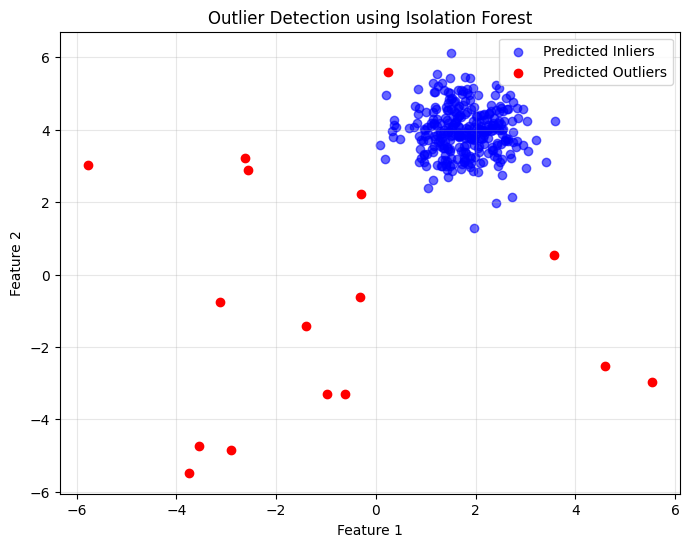

Predicted Inliers : 304
Predicted Outliers: 16
Normal Data Mean Anomaly Score : 0.1924 (Positive = Normal)
Outlier Data Mean Anomaly Score: -0.0602 (Negative = Outlier)


In [2]:
from sklearn.ensemble import IsolationForest

# 1. Pelatihan Isolation Forest
model_if = IsolationForest(n_estimators=100, contamination=0.05, random_state=2024)
model_if.fit(X_with_outliers)
y_pred_if = model_if.predict(X_with_outliers)

# 2. Ambil Skor Anomali Continuous
scores_if = model_if.decision_function(X_with_outliers)

# Visualisasi Hasil Isolation Forest
plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[y_pred_if == 1, 0],
            X_with_outliers[y_pred_if == 1, 1],
            color='blue', label='Predicted Inliers', alpha=0.6)
plt.scatter(X_with_outliers[y_pred_if == -1, 0],
            X_with_outliers[y_pred_if == -1, 1],
            color='red', label='Predicted Outliers')
plt.title("Outlier Detection using Isolation Forest")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Predicted Inliers : {(y_pred_if == 1).sum()}")
print(f"Predicted Outliers: {(y_pred_if == -1).sum()}")
print(f"Normal Data Mean Anomaly Score : {scores_if[:300].mean():.4f} (Positive = Normal)")
print(f"Outlier Data Mean Anomaly Score: {scores_if[300:].mean():.4f} (Negative = Outlier)")

- Mekanisme Kerja: Isolation Forest membangun 100 pohon isolasi acak. Outlier yang terletak jauh dari kluster dapat diisolasi pada kedalaman pohon yang sangat dangkal.

- Visualisasi & Skor: Menandai 16 titik sebagai outliers. Nilai decision_function untuk data normal bernilai positif ($+0.1924$), sedangkan untuk outliers bernilai negatif (rata-rata $-0.0602$), yang memberikan batas pemisah yang jelas.

# One-Class SVM for Novelty Detection

One-Class SVM dirancang khusus untuk skenario Novelty Detection:
1. Model hanya dilatih pada data normal (bersih dari outlier).
2. Menggunakan Kernel RBF untuk memetakan data normal ke ruang fitur berdimensi tinggi dan memisahkannya dari titik asal (origin) dengan hyperplane ber-margin maksimal.
3. Saat fase prediksi/pengujian, setiap data baru yang berada di luar batas keputusan (boundary) akan ditandai sebagai data anomali (novelty).

Parameter $\nu$ (nu) menentukan batas atas persentase data latih yang diperbolehkan berada di luar batas margin (training error rate).

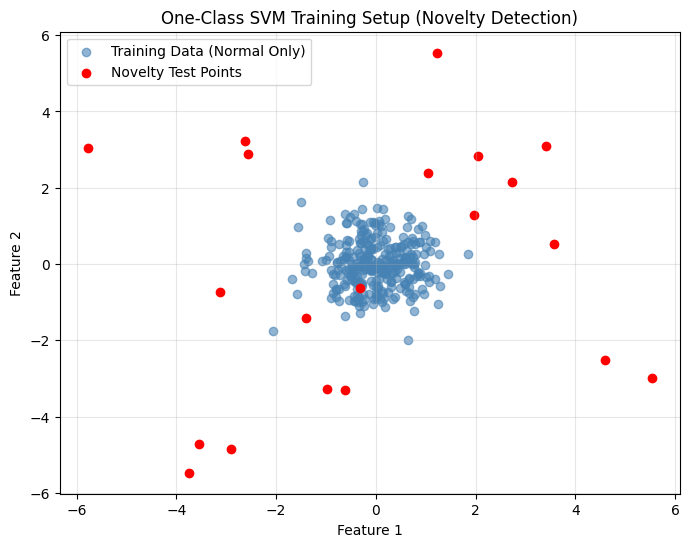

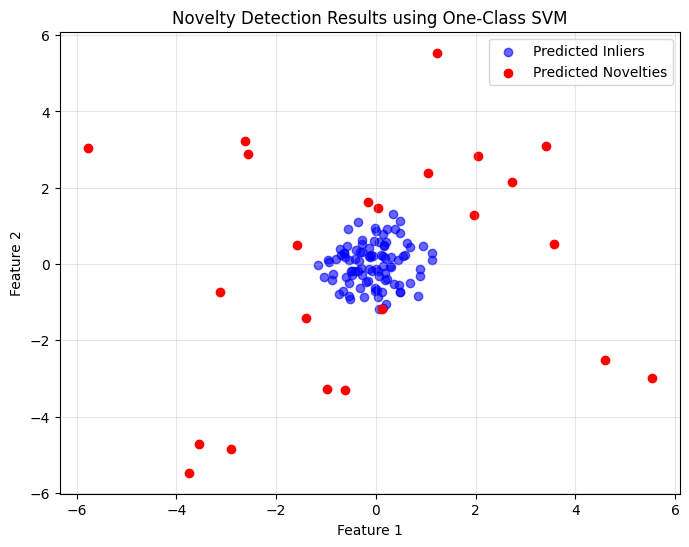

True Novelties Caught : 19 out of 20
Normal Test Misclassified: 4 out of 100


In [3]:
from sklearn.svm import OneClassSVM

# 1. Dataset Latih (HANYA Data Normal)
X_train_oc, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)

# 2. Dataset Uji (100 Normal Baru + 20 Novelties)
X_test_normal, _ = make_blobs(n_samples=100, centers=[[0, 0]], cluster_std=0.6, random_state=42)
np.random.seed(2024)
X_test_novelty = np.random.uniform(low=-6, high=6, size=(20, 2))
X_test = np.vstack([X_test_normal, X_test_novelty])

# Visualisasi Data Latih & Novelty
plt.figure(figsize=(8, 6))
plt.scatter(X_train_oc[:, 0], X_train_oc[:, 1], label='Training Data (Normal Only)', alpha=0.6, color='steelblue')
plt.scatter(X_test_novelty[:, 0], X_test_novelty[:, 1], color='red', label='Novelty Test Points')
plt.title("One-Class SVM Training Setup (Novelty Detection)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 3. Fit Model pada Data Latih Bersih, Predict pada Data Uji
model_svm = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
model_svm.fit(X_train_oc)
y_pred_svm = model_svm.predict(X_test)

# Visualisasi Prediksi One-Class SVM
plt.figure(figsize=(8, 6))
plt.scatter(X_test[y_pred_svm == 1, 0], X_test[y_pred_svm == 1, 1],
            color='blue', label='Predicted Inliers', alpha=0.6)
plt.scatter(X_test[y_pred_svm == -1, 0], X_test[y_pred_svm == -1, 1],
            color='red', label='Predicted Novelties')
plt.title("Novelty Detection Results using One-Class SVM")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

novelty_preds = y_pred_svm[100:]
normal_preds = y_pred_svm[:100]
print(f"True Novelties Caught : {(novelty_preds == -1).sum()} out of 20")
print(f"Normal Test Misclassified: {(normal_preds == -1).sum()} out of 100")

- Metodologi: Berbeda dengan LOF atau iForest, One-Class SVM melatih model tanpa pernah melihat contoh novelty sebelumnya.

- Hasil Evaluasi: Model berhasil menangkap 19 dari 20 data novelty ($95\%$ recall) dan hanya salah mengklasifikasikan 4 dari 100 data uji normal ($4\%$ false positive rate).

# Detecting Outliers with LOF across Varying-Density Clusters

Keunggulan utama LOF dibandingkan metode global (seperti iForest atau One-Class SVM) adalah kemampuannya menangani dataset yang memiliki kluster dengan tingkat kerapatan bervariasi (varying densities).

Metode global sering gagal karena menggunakan ambang batas jarak/isolasi yang sama di seluruh ruang fitur. Suatu titik yang terikat pada kluster renggang bisa dianggap outlier oleh metode global, namun LOF mengevaluasi titik tersebut hanya terhadap tetangga lokalnya (k-nearest neighbors):
$$\text{LOF}_{k}(p) = \frac{\sum_{o \in N_k(p)} \frac{\text{lrd}(o)}{\text{lrd}(p)}}{\vert{}N_k(p)\vert{}}$$

- Jika
LOF≈1: Kerapatan titik sama dengan tetangganya (Inlier).
- Jika $\text{LOF} \gg 1$: Kerapatan titik jauh lebih rendah dibanding tetangganya (Outlier).

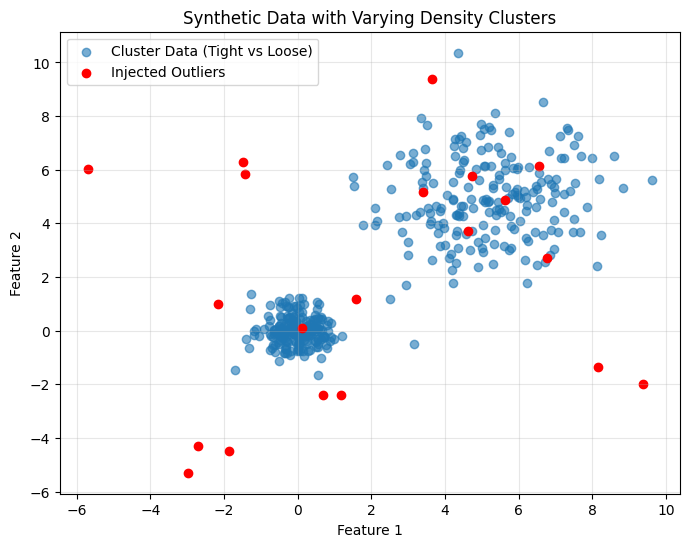

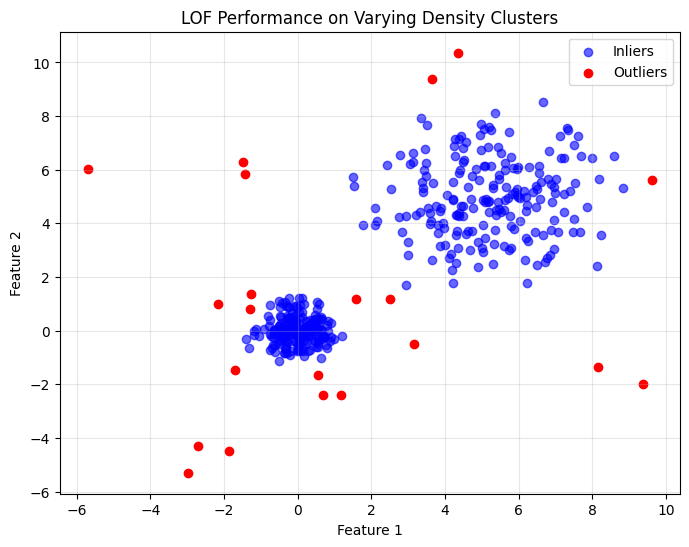

Normal Data Mean LOF Score : 1.1225
Outlier Data Mean LOF Score: 3.4366
Max LOF Score in Dataset   : 10.0368


In [4]:
# 1. Membuat Data dengan 2 Kluster Kerapatan Berbeda (Padat vs Renggang)
X_lof_dense, _ = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]],
                            cluster_std=[0.5, 1.5], random_state=2024)
np.random.seed(2024)
outliers_lof = np.random.uniform(low=-6, high=10, size=(20, 2))
X_lof_combined = np.vstack([X_lof_dense, outliers_lof])

# Visualisasi Data Kerapatan Bervariasi
plt.figure(figsize=(8, 6))
plt.scatter(X_lof_dense[:, 0], X_lof_dense[:, 1], label="Cluster Data (Tight vs Loose)", alpha=0.6)
plt.scatter(outliers_lof[:, 0], outliers_lof[:, 1], color='red', label="Injected Outliers")
plt.title("Synthetic Data with Varying Density Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 2. Fit LOF pada Data Kerapatan Bervariasi
lof_density = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred_lof_dens = lof_density.fit_predict(X_lof_combined)
lof_scores = -lof_density.negative_outlier_factor_

# Visualisasi Hasil Deteksi LOF
plt.figure(figsize=(8, 6))
plt.scatter(X_lof_combined[y_pred_lof_dens == 1, 0], X_lof_combined[y_pred_lof_dens == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_lof_combined[y_pred_lof_dens == -1, 0], X_lof_combined[y_pred_lof_dens == -1, 1],
            color='red', label='Outliers')
plt.title("LOF Performance on Varying Density Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Normal Data Mean LOF Score : {lof_scores[:400].mean():.4f}")
print(f"Outlier Data Mean LOF Score: {lof_scores[400:].mean():.4f}")
print(f"Max LOF Score in Dataset   : {lof_scores.max():.4f}")

- Grafik 1 (Kerapatan Bervariasi): Kluster kiri (pusat
[0,0]) sangat rapat (
σ=0.5), sedangkan kluster kanan (pusat
[5,5]) 3 kali lebih renggang (
σ=1.5).

- Grafik 2 (Hasil LOF): LOF membandingkan rasio kerapatan lokal. Skor rata-rata data normal adalah $1.1225$ (mendekati $1.0$), sedangkan outlier memiliki skor rata-rata $3.4366$ (terisolasi hingga 3.4x lipat dari kerapatan lokal tetangganya).

# Evaluating Outlier Detection Models

Akurasi ($Accuracy$) adalah metrik yang menyesatkan (misleading) pada kasus deteksi anomali karena kelas data sangat tidak seimbang (imbalanced). Sebagai contoh, jika outlier hanya $1\%$ dari total data, model naif yang menebak seluruh data sebagai "normal" akan mendapatkan akurasi $99\%$.

Metrik evaluasi yang tepat meliputi:
- Confusion Matrix: Menghitung $TN, FP, FN, TP$ secara transparan.
- Precision: $\frac{TP}{TP + FP}$ (Berapa persen tebakan outlier yang benar-benar outlier).
- Recall: $\frac{TP}{TP + FN}$ (Berapa persen total outlier asli yang berhasil ditangkap).
- ROC-AUC Score: Mengukur kemampuan model membedakan outlier dari inlier menggunakan skor kontinu, independen dari penentuan ambang batas (threshold).

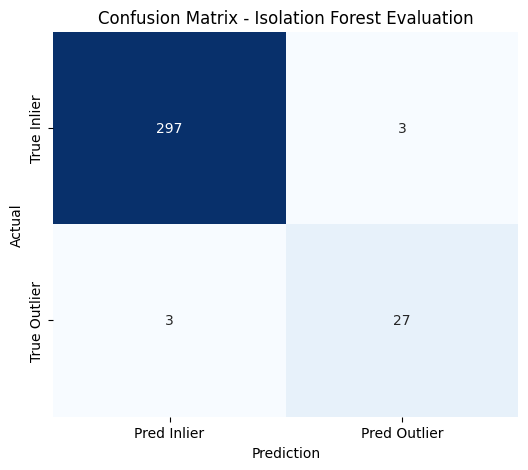

              precision    recall  f1-score   support

  Inlier (0)       0.99      0.99      0.99       300
 Outlier (1)       0.90      0.90      0.90        30

    accuracy                           0.98       330
   macro avg       0.95      0.95      0.95       330
weighted avg       0.98      0.98      0.98       330

ROC-AUC Score: 0.995


In [5]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns

# 1. Dataset Labeled untuk Evaluasi (300 Inliers + 30 Outliers = 9.1% Anomaly Rate)
X_inliers_eval, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers_eval = np.random.uniform(low=-6, high=6, size=(30, 2))
X_eval = np.vstack([X_inliers_eval, X_outliers_eval])
y_true = np.array([0] * 300 + [1] * 30)  # 0=Inlier, 1=Outlier

# 2. Fit Isolation Forest & Evaluasi
model_eval = IsolationForest(contamination=0.09, random_state=2024)
model_eval.fit(X_eval)
y_pred_eval = model_eval.predict(X_eval)
y_pred_binary = np.where(y_pred_eval == 1, 0, 1)  # Konversi: 1->0 (Inlier), -1->1 (Outlier)

# 3. Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred_binary)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Pred Inlier', 'Pred Outlier'],
            yticklabels=['True Inlier', 'True Outlier'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Isolation Forest Evaluation')
plt.show()

roc_auc = roc_auc_score(y_true, -model_eval.decision_function(X_eval))
print(classification_report(y_true, y_pred_binary, target_names=['Inlier (0)', 'Outlier (1)']))
print(f"ROC-AUC Score: {roc_auc:.3f}")

- Matrix Konfusi: Model berhasil mengidentifikasi 27 dari 30 outliers asli ($TP=27, FN=3$) dan memprediksi $297$ data normal dengan benar ($TN=297, FP=3$).

- Evaluasi Precision & Recall: Precision outlier bernilai
0.90 (
90% tebakan outlier benar) dan Recall bernilai
0.90 (
90% total outlier tertangkap). Skor ROC-AUC mencapai
0.995, membuktikan daya pisah skor anomali model yang sangat kuat.

# Handling Detected Outliers

Setelah outlier terdeteksi, terdapat tiga strategi utama penanganan:
1. Removal (Penghapusan): Menghapus baris outlier. Digunakan jika outlier disebabkan oleh eror pengukuran/sensor.
2. Median Replacement: Mengganti nilai outlier dengan nilai median dari data normal. Mempertahankan jumlah baris data.
3. Winsorization (Capping): Membatasi nilai ekstrim pada ambang persentil tertentu (misal $5\%$ terluar dibatasi ke kuantil ke-5 dan ke-95). Sangat berguna agar distribusi data tidak terdistorsi.

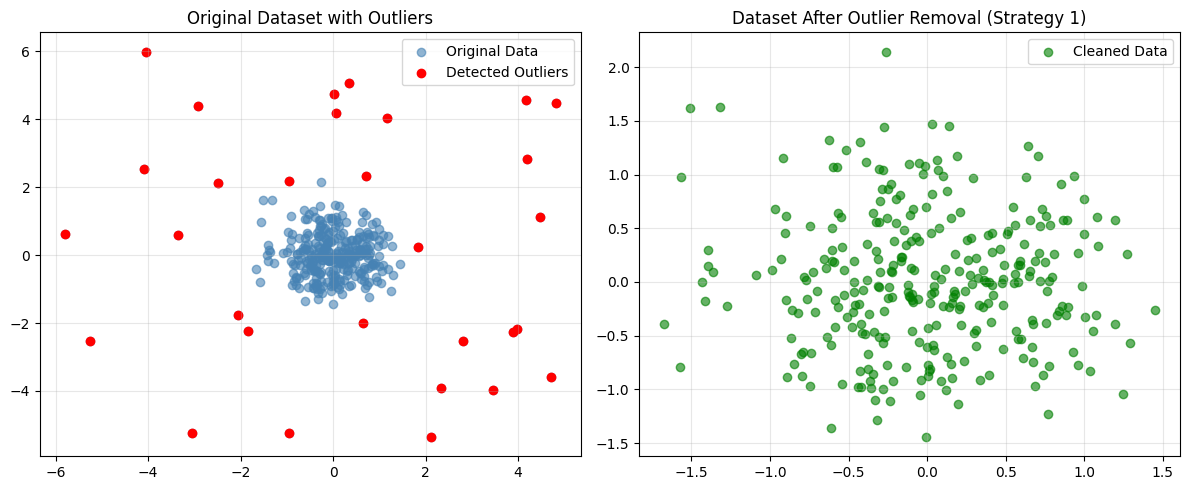

Original Data Size: 330
Cleaned Data Size : 300 (30 points removed)


In [6]:
# 1. Deteksi Mask Outliers Menggunakan Isolation Forest
outlier_mask = model_eval.predict(X_eval) == -1

# Strategy 1: Removal
X_cleaned = X_eval[~outlier_mask]

# Strategy 2: Median Replacement
X_replaced = X_eval.copy()
median_vals = np.median(X_eval[~outlier_mask], axis=0)
X_replaced[outlier_mask] = median_vals

# Strategy 3: Winsorization / Capping
X_df = pd.DataFrame(X_eval, columns=['feature1', 'feature2'])
X_capped = X_df.copy()
for col in X_df.columns:
    lower = X_df[col].quantile(0.05)
    upper = X_df[col].quantile(0.95)
    X_capped[col] = X_df[col].clip(lower=lower, upper=upper)

# Visualisasi Perbandingan (Original vs Cleaned)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_eval[:, 0], X_eval[:, 1], alpha=0.6, color='steelblue', label='Original Data')
plt.scatter(X_eval[outlier_mask][:, 0], X_eval[outlier_mask][:, 1], color='red', label='Detected Outliers')
plt.title("Original Dataset with Outliers")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.scatter(X_cleaned[:, 0], X_cleaned[:, 1], alpha=0.6, color='green', label='Cleaned Data')
plt.title("Dataset After Outlier Removal (Strategy 1)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Original Data Size: {X_eval.shape[0]}")
print(f"Cleaned Data Size : {X_cleaned.shape[0]} (30 points removed)")

- Strategi Removal (Grafik Kanan): Menghapus 30 titik pencilan sehingga ukuran data berkurang dari 330 menjadi 300 titik data bersih.

- Strategi Winsorization: Membatasi nilai ekstrim pada batas kuantil $5\%$ dan $95\%$ untuk menjaga struktur varians tanpa perlu membuang baris data.